## 1. Setup and imports

This notebook demonstrates **NumCompute-Stream** using a small synthetic classification dataset. The data is generated for demonstration purposes; it is not real student information. It uses only the Python standard library, NumPy, Matplotlib, and our own numcompute_stream package.

**Run from the repository root** (recommended), or from the demo directory. The CSV file should be located at assets/stream_demo.csv. Each section contains an explanation followed by a code cell.

In [9]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import os
project_root = Path.cwd()
if not (project_root / "numcompute_stream").is_dir():
    project_root = project_root.parent
os.chdir(project_root)
from numcompute_stream.io import load_csv_chunks
from numcompute_stream.preprocessing import ColumnSelector, SimpleImputer, StandardScaler, OneHotEncoder
from numcompute_stream.pipeline import Pipeline, FeatureUnion
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.visualise import (
    plot_metric_over_time,
    compare_models,
    plot_predictions_vs_ground_truth,
)


## 2. Read the CSV in chunks

For this demo, the example dataset contains Age, Score, and City as features, and Passed (0 or 1) as the classification target. `load_csv_chunks()` returns raw CSV values as a two-dimensional string array and returns the column names alongside each chunk. We use `chunk_size=30` so the streaming behaviour is easy to observe.

In [10]:
csv_path = Path("assets") / "stream_demo.csv"

print("CSV path:", csv_path.resolve())
print("File exists:", csv_path.exists())

chunk_size = 30

first_chunk, columns = next(
    load_csv_chunks(str(csv_path), chunk_size=chunk_size)
)

print("Columns:", columns)
print("First chunk shape:", first_chunk.shape)
print("First five rows:\n", first_chunk[:5])
assert "Passed" in columns
feature_columns = [name for name in columns if name != "Passed"]
print("Features:", feature_columns)

CSV path: E:\year 6\COMP 5004\Assignment-2.1-Programming-for-AI-Group_init_2\assets\stream_demo.csv
File exists: True
Columns: ['Age', 'Score', 'City', 'Passed']
First chunk shape: (30, 4)
First five rows:
 [['21' '83' 'Sydney' '1']
 ['36' '69' 'Sydney' '1']
 ['54' '64' 'Sydney' '1']
 ['33' '70' 'Adelaide' '0']
 ['54' '86' 'Adelaide' '1']]
Features: ['Age', 'Score', 'City']


## 3. Build the preprocessing and model pipeline

For this assignement, I used the same Pipeline + FeatureUnion structure as per Assignment 2.1 in our group design. Users will first which columns they want to process as categorical, and which columns they want to processs as numerical with the `ColumnSelector`, dividing into two pipelines. The numeric branch selects `Age` and `Score`, imputes missing numeric cells with 0, and applies `StandardScaler`. The categorical branch selects `City` and uses `OneHotEncoder`. Finally, a separate pipeline is created, where`DecisionTreeClassifier` is trained by buffered retraining. This helper lets us create fresh pipelines with different buffer sizes for comparison.

In [11]:
def build_pipeline(feature_columns, buffer_size=60):
    preprocessing = FeatureUnion([
        ("numeric", Pipeline([
            ("select", ColumnSelector(feature_columns, ["Age", "Score"])),
            ("imputer", SimpleImputer(fill_value=0, dtype=float)),
            ("scaler", StandardScaler()),
        ])),
        ("categorical", Pipeline([
            ("select", ColumnSelector(feature_columns, ["City"])),
            ("encoder", OneHotEncoder()),
        ])),
    ])

    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", DecisionTreeClassifier(
            max_depth=5,
            min_samples_split=2,
            buffer_size=buffer_size,
            criterion="gini",
        )),
    ])

pipeline = build_pipeline(feature_columns, buffer_size=60)
trainer = StreamTrainer(pipeline)
print("Streaming Pipeline and StreamTrainer created.")

Streaming Pipeline and StreamTrainer created.


## 4. Define the Test-Then-Train loop

For each CSV chunk, the package evaluates using the existing tree first, and train on the chunk afterwards. This avoids evaluating on data that has just been used for training. During Cold Start, the tree is not trained yet; `score_chunk()` records `None` for accuracy. We also collect pre-training predictions for the later Ground Truth comparison. A new tree root indicates a retraining event.

In [12]:
def run_stream(trainer, csv_path, chunk_size=30, verbose=True):
    all_true = []
    all_pred = []
    retrain_chunks = []

    for raw_chunk, chunk_columns in load_csv_chunks(str(csv_path), chunk_size=chunk_size):
        target_index = chunk_columns.index("Passed")
        X_chunk = np.delete(raw_chunk, target_index, axis=1)
        y_chunk = raw_chunk[:, target_index].astype(int)

        model = trainer.pipeline.steps[-1][1]
        if model.root is not None:
            predictions = trainer.pipeline.predict(X_chunk)
            all_true.extend(y_chunk.tolist())
            all_pred.extend(predictions.tolist())

        trainer.score_chunk(X_chunk, y_chunk)
        previous_root = model.root
        trainer.fit_chunk(X_chunk, y_chunk)

        if model.root is not None and model.root is not previous_root:
            retrain_chunks.append(len(trainer.history))

        if verbose:
            record = trainer.history[-1]
            acc = record["accuracy"]
            acc_text = "N/A (cold start)" if acc is None else f"{acc:.3f}"
            print(f"Chunk {record['chunk']:2d} | accuracy: {acc_text} "
                  f"| training time: {record['training_time']:.4f}s")

    return np.asarray(all_true, dtype=int), np.asarray(all_pred, dtype=int), retrain_chunks

## 5. Run the streaming experiment

Now we can use `run_stream()` to process the CSV one chunk at a time. We pass in the `StreamTrainer`, the CSV path, and a chunk size of 30. Because the decision tree has `buffer_size=60`, it will first train after receiving two chunks. From that point on, each new chunk is evaluated before being used for training, and the tree is retrained whenever another 60 samples have been collected. The code below prints the accuracy and training time for each chunk, along with a short summary at the end.

In [13]:
y_true_scored, y_pred_scored, retrain_chunks = run_stream(
    trainer, csv_path, chunk_size=chunk_size
)

print("\nProcessed chunks:", len(trainer.history))
print("Scored samples:", len(y_true_scored))
print("Retraining triggered after chunks:", retrain_chunks)
print("Final record:\n", trainer.history[-1])
assert len(trainer.history) == 10
assert len(y_true_scored) > 0

Chunk  1 | accuracy: N/A (cold start) | training time: 0.0024s
Chunk  2 | accuracy: N/A (cold start) | training time: 0.0228s
Chunk  3 | accuracy: 0.967 | training time: 0.0023s
Chunk  4 | accuracy: 0.867 | training time: 0.0175s
Chunk  5 | accuracy: 0.867 | training time: 0.0023s
Chunk  6 | accuracy: 0.833 | training time: 0.0248s
Chunk  7 | accuracy: 0.867 | training time: 0.0024s
Chunk  8 | accuracy: 0.900 | training time: 0.0156s
Chunk  9 | accuracy: 0.900 | training time: 0.0024s
Chunk 10 | accuracy: 0.867 | training time: 0.0365s

Processed chunks: 10
Scored samples: 240
Retraining triggered after chunks: [2, 4, 6, 8, 10]
Final record:
 {'chunk': 10, 'accuracy': 0.8666666666666667, 'cumulative_accuracy': 0.8833333333333333, 'cumulative_precision': 0.8823529411764706, 'cumulative_recall': 0.8823529411764706, 'cumulative_f1': 0.8823529411764706, 'cumulative_auc': 0.8907563025210083, 'training_time': 0.03645660006441176, 'peak_memory_mb': 0.03617095947265625}


## 6. Inspect streaming metrics

After running the stream, we can check the results stored in `trainer.history`. Each record contains the accuracy for that chunk and the cumulative metrics calculated from all evaluated samples so far. Here we print the final cumulative Accuracy, Precision, Recall, and F1, then look at the last three records to see what information is saved. The first two chunks have no scores because the model was still in Cold Start.

The history also includes training time and `peak_memory_mb`. The memory value comes from `tracemalloc`, so it is not the total RAM used by the Python process. The recorded training times include memory-tracing overhead and are useful for logging, but not for a controlled performance benchmark.


In [14]:
valid_records = [r for r in trainer.history if r["accuracy"] is not None]
last = trainer.history[-1]

print("Evaluated chunks:", len(valid_records))
for name in ("cumulative_accuracy", "cumulative_precision", "cumulative_recall", "cumulative_f1"):
    print(f"{name}: {last[name]:.4f}")

print("Last three history records:")
for record in trainer.history[-3:]:
    print(record)

assert 0.0 <= last["cumulative_accuracy"] <= 1.0

Evaluated chunks: 8
cumulative_accuracy: 0.8833
cumulative_precision: 0.8824
cumulative_recall: 0.8824
cumulative_f1: 0.8824
Last three history records:
{'chunk': 8, 'accuracy': 0.9, 'cumulative_accuracy': 0.8833333333333333, 'cumulative_precision': 0.8764044943820225, 'cumulative_recall': 0.8863636363636364, 'cumulative_f1': 0.8813559322033898, 'cumulative_auc': 0.8934041501976285, 'training_time': 0.0155510000186041, 'peak_memory_mb': 0.03617095947265625}
{'chunk': 9, 'accuracy': 0.9, 'cumulative_accuracy': 0.8857142857142857, 'cumulative_precision': 0.8725490196078431, 'cumulative_recall': 0.89, 'cumulative_f1': 0.8811881188118812, 'cumulative_auc': 0.8947272727272728, 'training_time': 0.002363900071941316, 'peak_memory_mb': 0.014097213745117188}
{'chunk': 10, 'accuracy': 0.8666666666666667, 'cumulative_accuracy': 0.8833333333333333, 'cumulative_precision': 0.8823529411764706, 'cumulative_recall': 0.8823529411764706, 'cumulative_f1': 0.8823529411764706, 'cumulative_auc': 0.890756302

## 7. Plot accuracy and F1 over time

We can use `plot_metric_over_time()` to visualise the results in `trainer.history`. In this example, we plot the accuracy of each chunk and the cumulative F1 score. This lets us see how the model performs on new chunks and how its overall performance changes as it receives more data. Chunks without predictions are kept as missing values rather than being shown as zero. The plots are displayed below and saved to `demo/outputs` for later use.

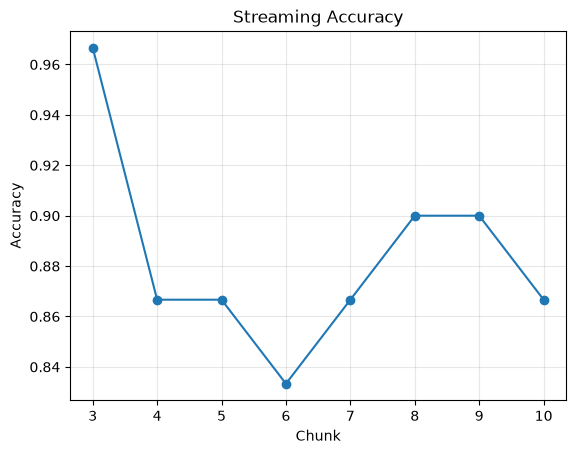

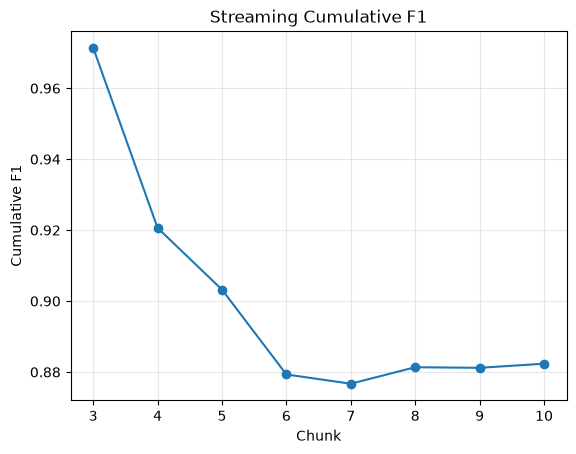

In [15]:
output_dir = project_root / "demo" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)
fig1 = plot_metric_over_time(
    trainer.history,
    metric="accuracy",
    save_path=str(output_dir / "chunk_accuracy.png"),
)
plt.show()
plt.close(fig1)

fig2 = plot_metric_over_time(
    trainer.history,
    metric="cumulative_f1",
    save_path=str(output_dir / "cumulative_f1.png"),
)
plt.show()
plt.close(fig2)

## 8. ROC-AUC Evaluation

ROC-AUC measures how well the model distinguishes between positive and negative classes using prediction scores. A higher AUC value indicates better classification performance, while an AUC of 0.5 represents random-level discrimination.

In this demo, we calculate Cumulative ROC-AUC using the true labels and prediction scores collected from all evaluated chunks so far. This allows us to observe how the model's overall performance changes as more data is processed.

Since the first two chunks are used for initial training, the model starts making predictions from Chunk 3. The following plot shows how Cumulative ROC-AUC changes throughout the streaming process. Unlike per-chunk accuracy, it uses all previously evaluated samples rather than only the current chunk.

Cumulative ROC-AUC: 0.8907563025210083


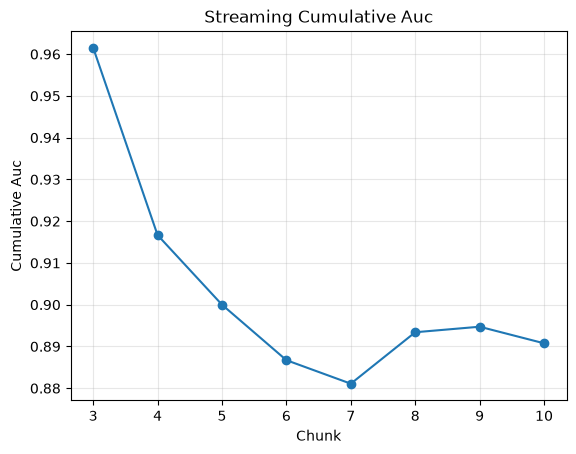

In [16]:

print("Cumulative ROC-AUC:", trainer.history[-1]["cumulative_auc"])

fig = plot_metric_over_time(
    trainer.history,
    metric="cumulative_auc",
    save_path="demo/outputs/cumulative_auc.png"
)

plt.show()
plt.close(fig)


### ROC Curve

The ROC Curve shows how well the model distinguishes between positive and negative classes at different prediction thresholds. The X-axis represents the False Positive Rate (FPR), while the Y-axis represents the True Positive Rate (TPR).

A curve closer to the top-left corner indicates better classification performance. The dashed diagonal line represents a random classifier with an AUC of 0.5.

In this demo, we use the true labels and prediction scores collected during the streaming evaluation to plot the ROC Curve. The AUC value summarises the overall performance of the model, with a higher value indicating better ability to distinguish between the two classes.

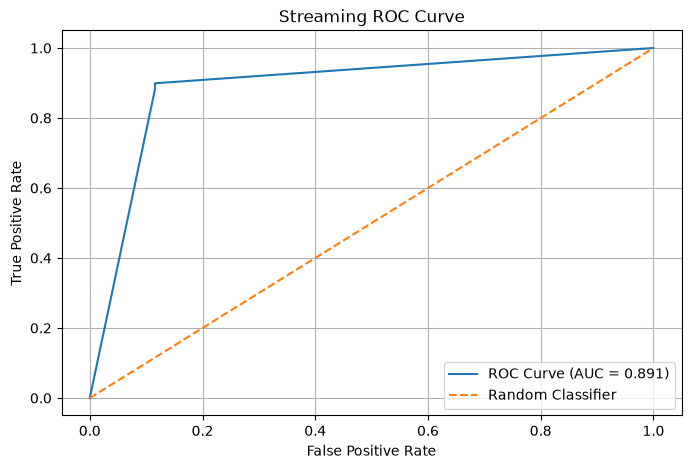

In [17]:

from numcompute_stream.metrics import roc_curve

y_true = np.concatenate(trainer.metrics._auc_true)
y_score = np.concatenate(trainer.metrics._auc_scores)

fpr, tpr, thresholds = roc_curve(y_true, y_score)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    fpr, tpr,
    label=f"ROC Curve (AUC = {trainer.history[-1]['cumulative_auc']:.3f})"
)

ax.plot([0, 1], [0, 1], "--", label="Random Classifier")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Streaming ROC Curve")
ax.legend()
ax.grid(True)

fig.savefig("demo/outputs/roc_curve.png")
plt.show()
plt.close(fig)


## 9. Compare predictions with Ground Truth

Another way to check the model is to compare its predictions with the actual `Passed` labels. Our `run_stream()` helper saved the predictions before each chunk was used for training, so we can use those results here. We show the first 40 evaluated samples to keep the plot readable. Samples from the Cold Start period are not included because the tree could not make predictions for them yet.

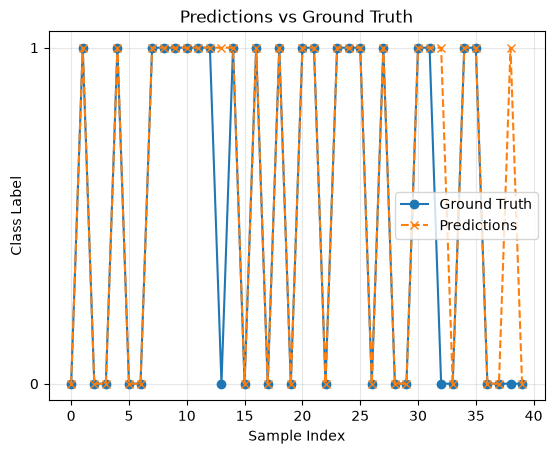

Displayed 40 evaluated samples.


In [18]:
n_display = min(40, len(y_true_scored))
fig3 = plot_predictions_vs_ground_truth(
    y_true_scored[:n_display],
    y_pred_scored[:n_display],
    save_path=str(output_dir / "predictions_vs_ground_truth.png"),
)
plt.show()
plt.close(fig3)
print("Displayed", n_display, "evaluated samples.")

## 10. Compare different buffer sizes

We can also use the same package functions to compare different buffer sizes. Here we create a new pipeline with `buffer_size=120`, while keeping the dataset and other model settings the same. We run it with a fresh `StreamTrainer` and use `compare_models()` to plot both cumulative accuracy histories together. Since the larger buffer needs more samples before its first training, the two models begin recording predictions at different chunks. This demonstrates how to compare streaming runs; a more controlled performance benchmark will be done separately.

In [ ]:
pipeline_120 = build_pipeline(feature_columns, buffer_size=120)
trainer_120 = StreamTrainer(pipeline_120)
_, _, retrain_chunks_120 = run_stream(
    trainer_120, csv_path, chunk_size=chunk_size, verbose=False
)

fig4 = compare_models(
    {"Buffer 60": trainer.history, "Buffer 120": trainer_120.history},
    metric="cumulative_accuracy",
    save_path=str(output_dir / "buffer_comparison.png"),
)
plt.show()
plt.close(fig4)

print("Buffer 60 retraining chunks:", retrain_chunks)
print("Buffer 120 retraining chunks:", retrain_chunks_120)
print("Saved charts in:", output_dir.resolve())